In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from matplotlib.patches import Wedge, Patch

from pymatgen.core import DummySpecies, Element, Lattice, Structure

In [2]:
## Make a simple 2D grid of atoms

A, B, X = DummySpecies("A"), Element("B"), DummySpecies("X")
spacing, vacuum = 3.0, 20.0
lattice = Lattice.tetragonal(4 * spacing, vacuum)
coords, species = [], []
for i in range(4):
    for j in range(4):
        coords.append([i / 4, j / 4, 0.5])
        species.append(X if i == 0 or j == 0 else {A: 6/9, B: 3/9})
structure = Structure(lattice, species, coords)
print(structure)

Full Formula (A6 X7 B3)
Reduced Formula: A6X7B3
abc   :  12.000000  12.000000  20.000000
angles:  90.000000  90.000000  90.000000
pbc   :       True       True       True
Sites (16)
  #  SP                     a     b    c
---  ------------------  ----  ----  ---
  0  X0+                 0     0     0.5
  1  X0+                 0     0.25  0.5
  2  X0+                 0     0.5   0.5
  3  X0+                 0     0.75  0.5
  4  X0+                 0.25  0     0.5
  5  A0+:0.667, B:0.333  0.25  0.25  0.5
  6  A0+:0.667, B:0.333  0.25  0.5   0.5
  7  A0+:0.667, B:0.333  0.25  0.75  0.5
  8  X0+                 0.5   0     0.5
  9  A0+:0.667, B:0.333  0.5   0.25  0.5
 10  A0+:0.667, B:0.333  0.5   0.5   0.5
 11  A0+:0.667, B:0.333  0.5   0.75  0.5
 12  X0+                 0.75  0     0.5
 13  A0+:0.667, B:0.333  0.75  0.25  0.5
 14  A0+:0.667, B:0.333  0.75  0.5   0.5
 15  A0+:0.667, B:0.333  0.75  0.75  0.5


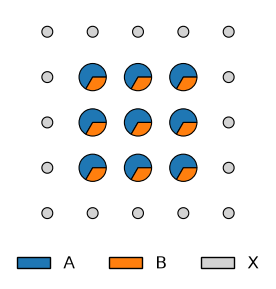

In [3]:
## Define a way to visualize the grid

def plot_grid(structure, show_legend=True, figsize=(3, 3), legend_fontsize=12, ax=None):
    colors = {"A": "tab:blue", "B": "tab:orange", "X": "lightgray"}
    xy = structure.cart_coords[:, :2]
    d = np.linalg.norm(xy[:, None] - xy[None, :], axis=-1)
    spacing = d[d > 1e-8].min() if np.any(d > 1e-8) else 1.0
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure
    positions, labels = [], set()
    for site in structure:
        shifts = [(0, 1) if np.isclose(f, 0) else (0,) for f in site.frac_coords[:2]]
        radius = spacing * (0.12 if all(s.symbol == "X" for s in site.species) else 0.3)
        for dx, dy in product(*shifts):
            pos = (site.coords + np.array([dx, dy, 0]) @ structure.lattice.matrix)[:2]
            positions.append(pos)
            angle = 0
            for species, occ in site.species.items():
                labels.add(species.symbol)
                ax.add_patch(Wedge(pos, radius, angle, angle + 360 * occ, facecolor=colors.get(species.symbol, "gray"), edgecolor="black", linewidth=0.8))
                angle += 360 * occ
    positions = np.array(positions)
    ax.set(xlim=(positions[:, 0].min() - spacing / 2, positions[:, 0].max() + spacing / 2), ylim=(positions[:, 1].min() - spacing / 2, positions[:, 1].max() + spacing / 2), aspect="equal")
    ax.set_axis_off()
    if show_legend:
        ax.legend(handles=[Patch(facecolor=colors.get(s, "gray"), edgecolor="black", label=s) for s in sorted(labels)], loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=len(labels), frameon=False, fontsize=legend_fontsize)
    fig.tight_layout()
    return fig, ax

def plot_configurations(structures, titles, ncols=4, size=2.2):
    nrows = -(-len(structures) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.flat[len(structures):]:
        ax.set_axis_off()
    for s, title, ax in zip(structures, titles, axes.flat):
        plot_grid(s, show_legend=False, ax=ax)
        ax.set_title(title, fontsize=10)
    fig.tight_layout()
    plt.show()

fig, ax = plot_grid(structure)
plt.show()

In [4]:
from disorder_mc import count_configurations, count_distinct_configurations

print(count_configurations(structure))
print(count_distinct_configurations(structure))

84
16


(<Figure size 300x300 with 1 Axes>, <Axes: >)

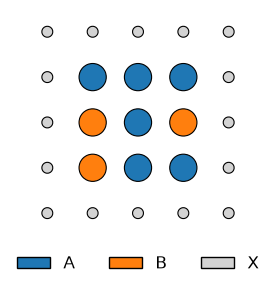

In [5]:
from disorder_mc import random_ordered_configuration, random_energy_sampling

random_ordering=random_ordered_configuration(structure, np.random.default_rng(0))
plot_grid(random_ordering)

## An energy that penalizes A–B neighbors

A simple model energy: every nearest-neighbor A–B pair costs $J$,

$$E = J \, N_{AB},$$

where $N_{AB}$ is the number of A–B nearest-neighbor bonds (sites `spacing` apart). This favors configurations that cluster the B atoms together. The X frame separates each 3×3 block from its periodic images, so only A–B bonds inside a block count. We take $J = 1$, so energies are in units of $J$ (the samplers label energies as eV, but for this toy model they are just bond counts).

In [6]:
J = 1.0

def ab_bond_energy(configuration):
    """E = J * (number of nearest-neighbor A-B pairs)."""
    neighbors = configuration.get_all_neighbors(1.1 * spacing)
    n_ab = sum(
        {site.specie.symbol, neighbor.specie.symbol} == {"A", "B"}
        for site, site_neighbors in zip(configuration, neighbors)
        for neighbor in site_neighbors
    ) // 2  # each bond is seen from both ends
    return {"energy": J * n_ab, "n_AB_bonds": n_ab}

ab_bond_energy(random_ordering)

{'energy': 6.0, 'n_AB_bonds': 6}

## Random energy sampling

Generate random orderings, score them with `ab_bond_energy`, remove symmetry duplicates, and keep the lowest-energy distinct configurations.

There are only 84 orderings here, so the low-energy ones come up again and again. By default the sampler keeps only the `max(5 * n_return, 50)` lowest-energy attempts before removing duplicates, and here that pool would hold nothing but copies of the two best orderings. Setting `candidate_pool_size = n_attempts` keeps every attempt, so every distinct ordering that was sampled can be returned. The degeneracy $g$ is the number of orderings related to each one by the parent's symmetry.

returned 16 distinct configurations
attempt   20: E =  3J, g = 4
attempt   55: E =  4J, g = 4
attempt    5: E =  5J, g = 8
attempt   15: E =  5J, g = 8
attempt   32: E =  5J, g = 8
attempt    0: E =  6J, g = 4
attempt    2: E =  6J, g = 8
attempt    3: E =  6J, g = 8
attempt   12: E =  6J, g = 4
attempt   16: E =  6J, g = 2
attempt    1: E =  7J, g = 4
attempt   29: E =  7J, g = 8
attempt   10: E =  8J, g = 2
attempt   22: E =  8J, g = 4
attempt   26: E =  8J, g = 4
attempt    8: E =  9J, g = 4


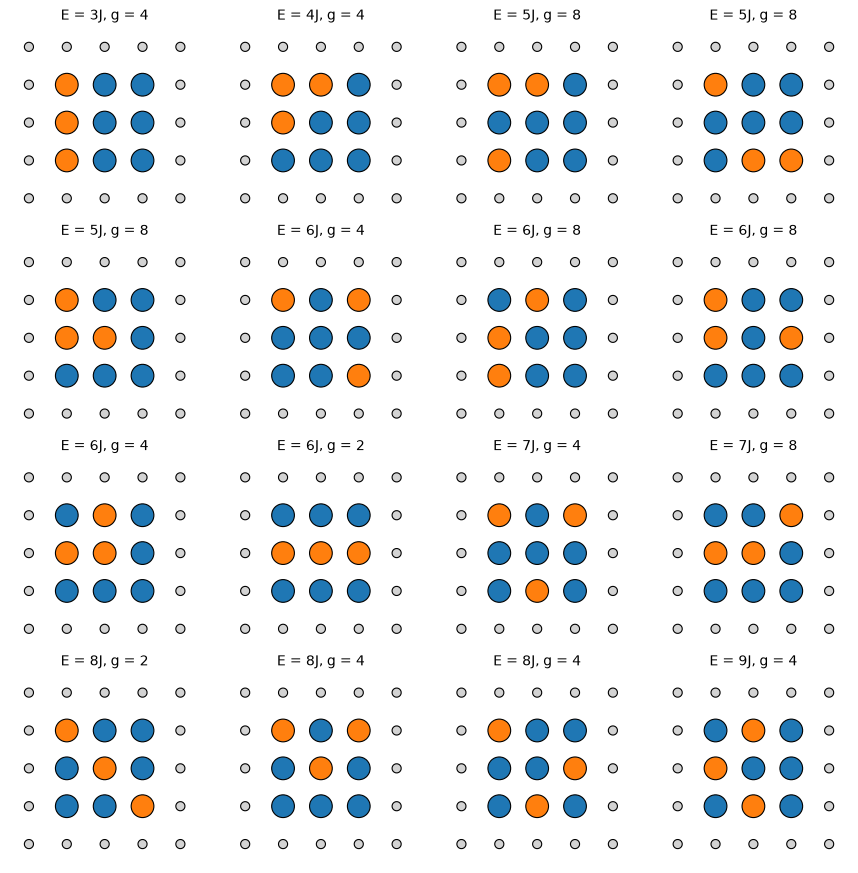

In [13]:
from disorder_mc import configuration_degeneracy

n_attempts = 500
sampled = random_energy_sampling(
    structure,
    ab_bond_energy,
    n_attempts=n_attempts,
    n_return=16,
    seed=16,
    candidate_pool_size=n_attempts,
    verbose=False,
)
sampled_g = [configuration_degeneracy(structure, c.structure) for c in sampled]

print(f"returned {len(sampled)} distinct configurations")
for config, g in zip(sampled, sampled_g):
    print(f"attempt {config.step:>4d}: E ={config.energy:3.0f}J, g = {g}")

plot_configurations(
    [c.structure for c in sampled],
    [f"E = {c.energy:.0f}J, g = {g}" for c, g in zip(sampled, sampled_g)],
)

## Exact enumeration

`enumerate_ordered_configurations` (which uses icet; install with the `icet` extra) yields exactly one ordering from each set of symmetry-equivalent orderings. Their degeneracies must add up to the total number of orderings.

16 distinct configurations
sum of degeneracies = 84 (total orderings = 84)
E =   3 J | g = 4
E =   4 J | g = 4
E =   5 J | g = 8
E =   5 J | g = 8
E =   5 J | g = 8
E =   6 J | g = 2
E =   6 J | g = 4
E =   6 J | g = 4
E =   6 J | g = 8
E =   6 J | g = 8
E =   7 J | g = 4
E =   7 J | g = 8
E =   8 J | g = 2
E =   8 J | g = 4
E =   8 J | g = 4
E =   9 J | g = 4


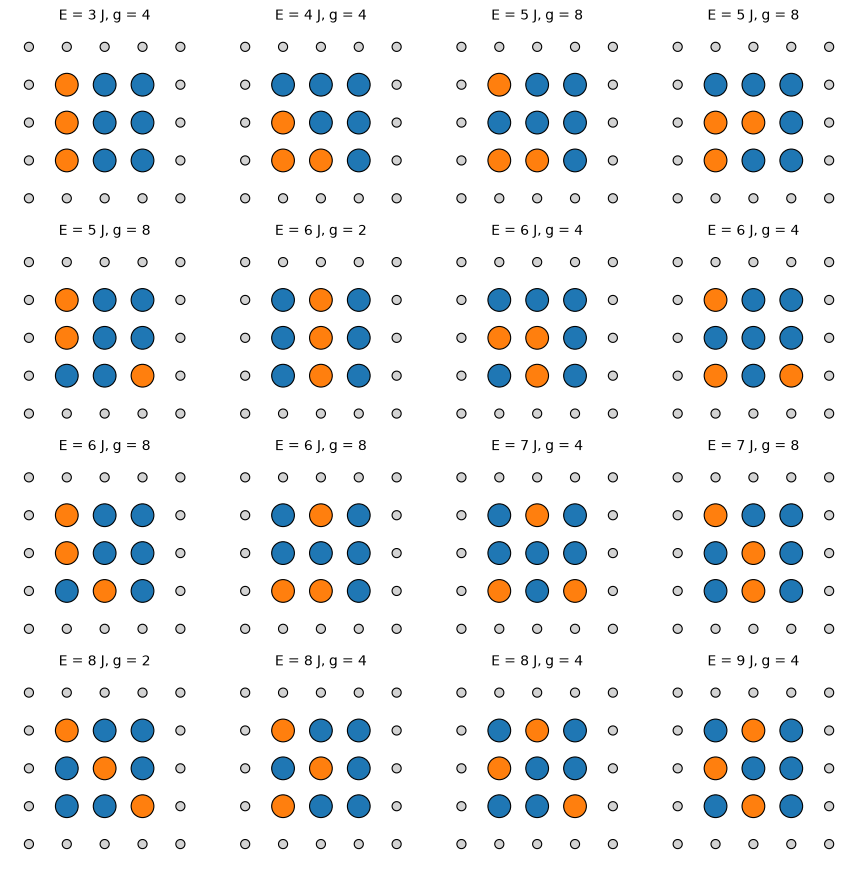

In [8]:
from disorder_mc import enumerate_ordered_configurations

exact = sorted(
    (
        (ab_bond_energy(c)["energy"], configuration_degeneracy(structure, c), c)
        for c in enumerate_ordered_configurations(structure)
    ),
    key=lambda row: row[:2],
)

print(f"{len(exact)} distinct configurations")
print(f"sum of degeneracies = {sum(g for _, g, _ in exact)} "
      f"(total orderings = {count_configurations(structure)})")
for energy, g, _ in exact:
    print(f"E = {energy:3.0f} J | g = {g}")

plot_configurations(
    [c for _, _, c in exact],
    [f"E = {energy:.0f} J, g = {g}" for energy, g, _ in exact],
)

## Comparing the two

With enough attempts, random sampling should find every distinct configuration, so its list of (energy, degeneracy) pairs should match exact enumeration. The Boltzmann-weighted average energy is computed from the exact list.

In [9]:
sampled_spectrum = sorted((c.energy, g) for c, g in zip(sampled, sampled_g))
exact_spectrum = [(energy, g) for energy, g, _ in exact]
print("sampled matches exact:", sampled_spectrum == exact_spectrum)
print(f"ground state: E = {exact_spectrum[0][0]:.0f} J, g = {exact_spectrum[0][1]}")

energies = np.array([energy for energy, _ in exact_spectrum])
weights = np.array([g for _, g in exact_spectrum])
for kT in (0.5, 1.0, 2.0, np.inf):
    boltzmann = weights * np.exp(-(energies - energies.min()) / kT)
    print(f"kT = {kT:>4} J: <E> = {np.sum(boltzmann * energies) / boltzmann.sum():.3f} J")

sampled matches exact: True
ground state: E = 3 J, g = 4
kT =  0.5 J: <E> = 3.323 J
kT =  1.0 J: <E> = 4.273 J
kT =  2.0 J: <E> = 5.079 J
kT =  inf J: <E> = 6.000 J
